# Clustering · Quels types de clients à Comtoise Market ?

[![Ouvrir dans Google Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/josephazar/ELC2-Introduction-IA-2026/blob/main/seance-3/ia-elc2/05-clustering.ipynb)

**ELC2 · Introduction au machine learning · Séance 3**

**Comtoise Market**, un supermarché fictif de Franche-Comté, a **600 clients** avec une carte de fidélité. La direction voudrait
des **offres différentes selon les types de clients**. Mais personne n'a jamais rangé les clients dans des catégories : il n'y a
**aucune colonne « réponse »**. C'est un problème de **clustering** : trouver des **groupes** de clients qui se ressemblent, sans que
les groupes soient connus à l'avance.

Le fichier est **propre** (séance 1 faite) et **fictif**. Ce notebook :

1. regarde les clients, et rappelle ce que veut dire « se ressembler » (la **distance**) ;
2. déroule **K-Means à la main** sur 9 clients, puis le fait faire à Python ;
3. **standardise** les colonnes, et choisit le **nombre de groupes** (coude, silhouette) ;
4. **lit** les 4 groupes trouvés sur les 600 clients ;
5. essaie deux autres méthodes : le clustering **hiérarchique** et **DBSCAN** ;
6. dessine les 5 colonnes sur un plan avec la **PCA**.

Vous n'avez **rien à écrire** : il suffit d'exécuter les cellules, dans l'ordre, avec
**Maj + Entrée** dans Jupyter (**Exécution → Tout exécuter** sur Google Colab). Sur GitHub, le
notebook s'affiche avec ses résultats : il se lit comme un guide.

## 0. Vérifier que tout est prêt

Cette cellule dit où tourne votre notebook. Sur votre ordinateur, ce doit être le Python du
dossier `.venv` de votre dossier `ia-elc2`. Sur Google Colab, il n'y a rien à vérifier.

In [1]:
import sys
from pathlib import Path

python_utilise = Path(sys.executable)

if "google.colab" in sys.modules:
    print("OK : vous êtes sur Google Colab, il n'y a rien à installer.")
elif ".venv" in python_utilise.parts:
    print("Python utilisé :", ".../" + "/".join(python_utilise.parts[-4:]))
    print("OK : ce notebook tourne dans l'environnement virtuel du cours.")
else:
    print("Python utilisé :", python_utilise)
    print("ATTENTION : ce n'est pas le Python du cours. Relisez le guide d'installation.")

Python utilisé : .../ia-elc2/.venv/bin/python
OK : ce notebook tourne dans l'environnement virtuel du cours.


Les deux fichiers de données sont-ils là ? Sur votre ordinateur, ils sont dans le dossier `donnees`.
Sur Google Colab, cette cellule les télécharge depuis la page GitHub du cours.

In [2]:
from urllib.request import urlretrieve

for nom in ["clients-comtoise-market.csv", "formes.csv"]:
    fichier = Path("donnees") / nom
    if not fichier.exists():
        fichier.parent.mkdir(exist_ok=True)
        urlretrieve("https://raw.githubusercontent.com/josephazar/ELC2-Introduction-IA-2026/main/seance-3/ia-elc2/donnees/" + nom, fichier)
        print("Fichier téléchargé depuis GitHub :", nom)

print("Données prêtes.")

Données prêtes.


On charge les bibliothèques, et on règle l'allure des graphiques une fois pour toutes.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

plt.rcParams.update({
    "figure.dpi": 100,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.alpha": 0.25,
    "axes.axisbelow": True,
})
BLEU, ORANGE, TURQUOISE, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#4a3aa7"
COULEURS = [BLEU, ORANGE, TURQUOISE, VIOLET]      # toujours dans cet ordre : un groupe garde sa couleur
GRIS = "#9aa5b1"

---
# Partie 1 · Les clients

## 1. Le fichier

In [4]:
clients = pd.read_csv("donnees/clients-comtoise-market.csv")
clients.head(8)

,id_client,age,visites_par_mois,panier_moyen,part_promo,part_bio
0,M-0001,66,12,28.7,17,19
1,M-0002,39,10,91.0,38,8
2,M-0003,26,5,26.7,56,11
3,M-0004,68,8,42.3,17,29
4,M-0005,55,14,37.1,20,9
5,M-0006,21,2,17.5,59,5
6,M-0007,44,9,79.4,31,13
7,M-0008,74,12,34.0,11,25


Une ligne par client. Voici le sens des colonnes :

| Colonne | Sens |
|---|---|
| `id_client` | numéro de carte (ne décrit pas le client : on ne s'en servira pas) |
| `age` | âge en années |
| `visites_par_mois` | nombre de passages en magasin par mois |
| `panier_moyen` | montant moyen d'un passage, en euros |
| `part_promo` | part des achats faits en promotion, en % |
| `part_bio` | part des achats en produits bio, en % |

**Il n'y a pas de colonne « réponse ».** Aucune cible à deviner : on cherche seulement **qui ressemble à qui**.

In [5]:
print("lignes, colonnes :", clients.shape)
print("cases vides      :", clients.isna().sum().sum())
print("lignes en double :", clients.duplicated().sum())
clients.describe().round(1)

lignes, colonnes : (600, 6)
cases vides      : 0
lignes en double : 0


,age,visites_par_mois,panier_moyen,part_promo,part_bio
count,600.0,600.0,600.0,600.0,600.0
mean,42.8,8.2,55.4,29.2,24.0
std,16.9,4.0,32.2,18.9,21.3
min,18.0,1.0,6.3,0.0,0.0
25%,28.0,5.0,24.5,13.0,10.0
50%,40.0,7.0,47.8,27.0,15.5
75%,55.0,10.0,84.6,41.0,26.0
max,84.0,20.0,136.6,78.0,91.0


## 2. Regarder avant de regrouper

Trois dessins, chacun avec **deux colonnes sur cinq**. Tous les points sont gris : personne ne sait encore qui est qui.

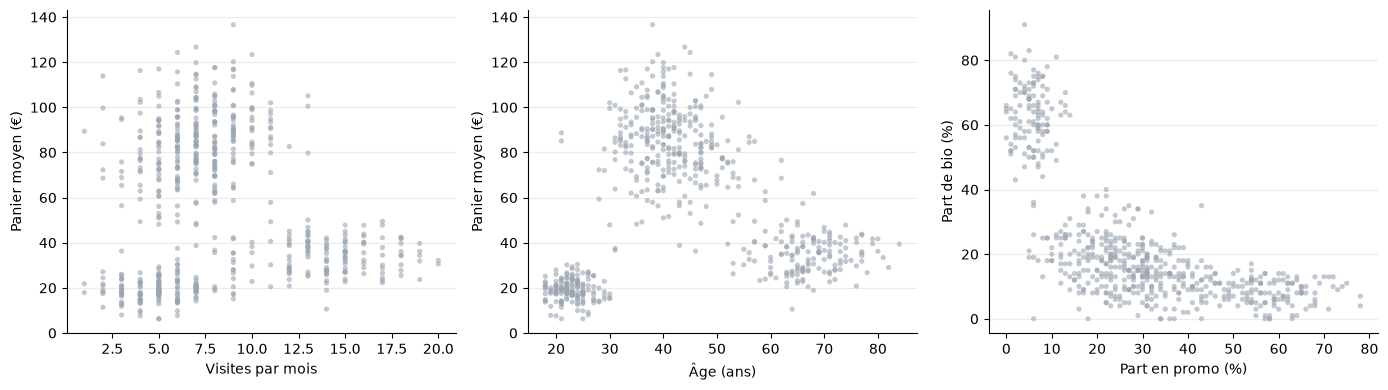

In [6]:
paires = [("visites_par_mois", "panier_moyen", "Visites par mois", "Panier moyen (€)"),
          ("age", "panier_moyen", "Âge (ans)", "Panier moyen (€)"),
          ("part_promo", "part_bio", "Part en promo (%)", "Part de bio (%)")]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (x_col, y_col, x_nom, y_nom) in zip(axes, paires):
    ax.scatter(clients[x_col], clients[y_col], s=14, color=GRIS, alpha=0.6, edgecolor="none")
    ax.set_xlabel(x_nom)
    ax.set_ylabel(y_nom)
plt.tight_layout()
plt.show()

À l'œil, on devine des **amas** : un groupe à petits paniers et peu de visites, un groupe à gros paniers, un groupe qui
vient très souvent. Mais avec **cinq colonnes**, l'œil ne suffit plus. On demande à l'ordinateur de chercher les groupes
**à notre place**.

---
# Partie 2 · K-Means à la main

## 3. Se ressembler, c'est être proche : la distance

Deux clients **se ressemblent** si leurs chiffres sont **proches**. On mesure cette proximité par la **distance** : la
longueur de la ligne droite qui les relie. La formule vient de **Pythagore** : l'écart sur chaque colonne forme un côté d'un
triangle rectangle, et la distance est la ligne droite entre les deux (l'hypoténuse).

**distance = √( écart₁² + écart₂² )**

Neuf clients, aux chiffres arrondis pour calculer à la main (visites par mois, et panier en dizaines d'euros) : ce sont
les neuf clients du cours.

In [7]:
noms = list("ABCDEFGHI")
points = np.array([[4, 2], [5, 1], [5, 2], [6, 7], [8, 10], [8, 11], [13, 4], [15, 4], [14, 2]], dtype=float)

neuf = pd.DataFrame(points, index=noms, columns=["visites par mois", "panier (× 10 €)"])
neuf

,visites par mois,panier (× 10 €)
A,4.0,2.0
B,5.0,1.0
C,5.0,2.0
D,6.0,7.0
E,8.0,10.0
F,8.0,11.0
G,13.0,4.0
H,15.0,4.0
I,14.0,2.0


In [8]:
# distance entre le client G (13 ; 4) et le client C (5 ; 2)
g = points[noms.index("G")]
c = points[noms.index("C")]
ecart_visites, ecart_panier = g - c
print("écarts :", ecart_visites, "et", ecart_panier)
print("distance =", round(float(np.sqrt(ecart_visites ** 2 + ecart_panier ** 2)), 2), " (c'est √68)")

écarts : 8.0 et 2.0
distance = 8.25  (c'est √68)


## 4. K-Means en quatre gestes

**K** est le nombre de groupes qu'on demande. Ici K = 3.

1. **Choisir** K points au hasard : les **centres**.
2. **Rattacher** chaque client au centre le plus proche.
3. **Déplacer** chaque centre au milieu (la **moyenne**) de son groupe. La moyenne est le point « au milieu » du groupe,
   celui qui est, au total, le plus proche de tous ses clients.
4. **Recommencer** les gestes 2 et 3 jusqu'à ce que plus rien ne bouge.

On écrit ces gestes en Python, **sans** l'outil de scikit-learn, pour voir ce qu'il fait. Le tirage de départ est celui du
cours : les clients **A, C et F** (un tirage volontairement mauvais : A et C sont côte à côte).

In [9]:
centres = points[[0, 2, 5]].copy()        # geste 1 : les centres de départ sont les clients A, C et F
historique = []                           # on garde chaque tour, pour le dessiner ensuite

for tour in range(1, 10):
    # geste 2 : la distance de chaque client à chacun des 3 centres
    distances = np.zeros((9, 3))
    for i in range(9):
        for k in range(3):
            distances[i, k] = np.sqrt(((points[i] - centres[k]) ** 2).sum())

    groupes = distances.argmin(axis=1)    # argmin : le numéro du centre le plus proche (0, 1 ou 2)

    tableau = pd.DataFrame(distances.round(2), index=noms, columns=["centre 1", "centre 2", "centre 3"])
    tableau["groupe"] = groupes + 1
    print(f"--- Tour {tour} : les distances, et le groupe de chaque client")
    display(tableau)
    historique.append((centres.copy(), groupes.copy()))

    # a-t-on fini ? si aucun client n'a changé de groupe, oui
    if tour > 1 and (groupes == historique[-2][1]).all():
        print("Aucun client n'a changé de groupe : l'algorithme s'arrête.")
        break

    # geste 3 : chaque centre va à la moyenne de ses clients
    centres = np.array([points[groupes == k].mean(axis=0) for k in range(3)])
    print("nouveaux centres :", centres.round(2).tolist())

--- Tour 1 : les distances, et le groupe de chaque client


,centre 1,centre 2,centre 3,groupe
A,0.00,1.00,9.85,1
B,1.41,1.00,10.44,2
C,1.00,0.00,9.49,2
D,5.39,5.10,4.47,3
E,8.94,8.54,1.00,3
F,9.85,9.49,0.00,3
G,9.22,8.25,8.60,2
H,11.18,10.20,9.90,3
I,10.00,9.00,10.82,2


nouveaux centres : [[4.0, 2.0], [9.25, 2.25], [9.25, 8.0]]
--- Tour 2 : les distances, et le groupe de chaque client


,centre 1,centre 2,centre 3,groupe
A,0.00,5.26,7.97,1
B,1.41,4.43,8.19,1
C,1.00,4.26,7.35,1
D,5.39,5.76,3.40,3
E,8.94,7.85,2.36,3
F,9.85,8.84,3.25,3
G,9.22,4.14,5.48,2
H,11.18,6.01,7.00,2
I,10.00,4.76,7.65,2


nouveaux centres : [[4.67, 1.67], [14.0, 3.33], [7.33, 9.33]]
--- Tour 3 : les distances, et le groupe de chaque client


,centre 1,centre 2,centre 3,groupe
A,0.75,10.09,8.06,1
B,0.75,9.30,8.65,1
C,0.47,9.10,7.70,1
D,5.50,8.80,2.69,3
E,8.98,8.97,0.94,3
F,9.91,9.74,1.80,3
G,8.65,1.20,7.78,2
H,10.59,1.20,9.34,2
I,9.34,1.33,9.91,2


Aucun client n'a changé de groupe : l'algorithme s'arrête.


Lecture :

- **tour 1** : avec deux centres côte à côte (A et C), le client G, par exemple, va au centre 2 (distance 8,25, contre 8,60
  pour le centre 3) ; les centres sont ensuite déplacés à la moyenne de leurs clients ;
- **tour 2** : les centres déplacés **corrigent** le mauvais tirage : B, C et H **changent de groupe** ;
- **tour 3** : plus personne ne change de groupe. Fini, en trois tours.

Dessinons les trois tours.

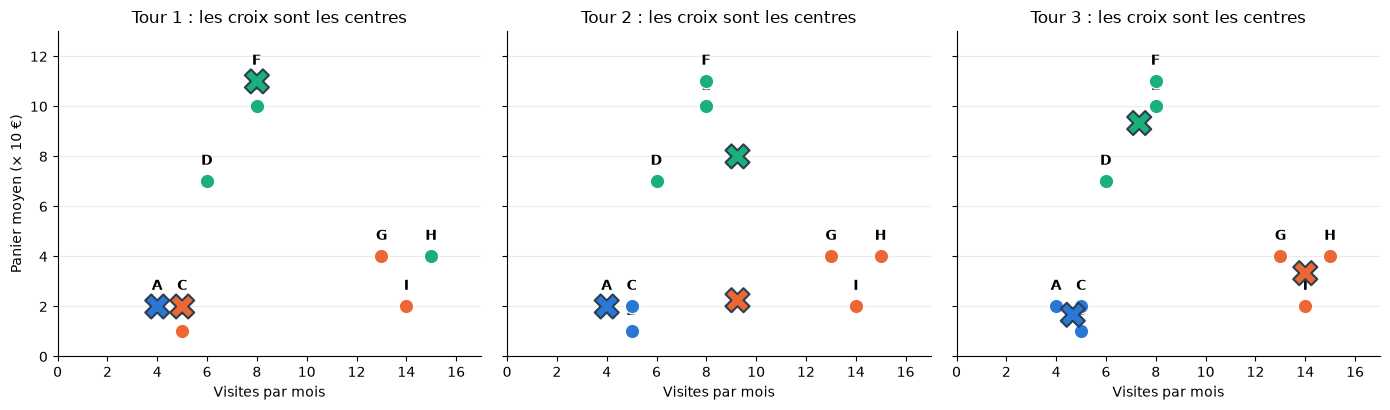

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, (tour, (c, g)) in zip(axes, enumerate(historique, start=1)):
    for k in range(3):
        ax.scatter(points[g == k, 0], points[g == k, 1], s=110, color=COULEURS[k], edgecolor="white", zorder=4)
    ax.scatter(c[:, 0], c[:, 1], s=300, marker="X", c=COULEURS[:3], edgecolor="#2c3e50", linewidth=1.5, zorder=5)
    for nom, (px, py) in zip(noms, points):
        ax.annotate(nom, (px, py), xytext=(0, 12), textcoords="offset points", ha="center", fontweight="bold")
    ax.set_title(f"Tour {tour} : les croix sont les centres")
    ax.set_xlabel("Visites par mois")
    ax.set_xlim(0, 17)
    ax.set_ylim(0, 13)
axes[0].set_ylabel("Panier moyen (× 10 €)")
plt.tight_layout()
plt.show()

**Vérification.** `KMeans` de scikit-learn fait ces gestes. Si on lui donne les mêmes centres de départ, il doit
trouver **les mêmes centres finaux**.

In [11]:
from sklearn.cluster import KMeans

km_neuf = KMeans(n_clusters=3, init=points[[0, 2, 5]], n_init=1)
km_neuf.fit(points)

print("centres finaux de scikit-learn :")
print(km_neuf.cluster_centers_.round(2))
print("centres finaux de notre boucle :")
print(centres.round(2))
print("inertie :", round(km_neuf.inertia_, 2))

centres finaux de scikit-learn :
[[ 4.67  1.67]
 [14.    3.33]
 [ 7.33  9.33]]
centres finaux de notre boucle :
[[ 4.67  1.67]
 [14.    3.33]
 [ 7.33  9.33]]
inertie : 17.33


Mêmes centres : `KMeans` n'a rien de magique. L'**inertie** est la somme des distances au carré entre chaque client et
son centre. Plus elle est petite, plus les groupes sont **serrés**.

Ces 9 clients forment trois groupes qu'on peut **nommer** en regardant leurs chiffres :

- **A, B, C** : 4 à 5 visites par mois, petits paniers (10 à 20 €) ;
- **D, E, F** : 6 à 8 visites, gros paniers (70 à 110 €) ;
- **G, H, I** : 13 à 15 visites, paniers moyens (20 à 40 €).

**À nous de nommer** : étudiants, familles, seniors fidèles ? L'algorithme ne sait pas ce que veut dire « famille » ; il
a seulement rapproché des chiffres.

---
# Partie 3 · Les 600 clients

## 5. Standardiser avant de regrouper

K-Means compare des **distances**. Or nos colonnes n'ont pas la même **échelle** : le panier se compte en dizaines d'euros, les
visites en unités. Regardons.

In [12]:
colonnes = ["age", "visites_par_mois", "panier_moyen", "part_promo", "part_bio"]
clients[colonnes].agg(["min", "max", "std"]).round(1)

,age,visites_par_mois,panier_moyen,part_promo,part_bio
min,18.0,1.0,6.3,0.0,0.0
max,84.0,20.0,136.6,78.0,91.0
std,16.9,4.0,32.2,18.9,21.3


Le panier varie beaucoup plus que les visites (écart-type 32 contre 4). Dans un calcul de distance, **le panier écraserait les
visites**. Essayons, sur deux colonnes seulement : K-Means avec K = 3, **sans** puis **avec** standardisation.

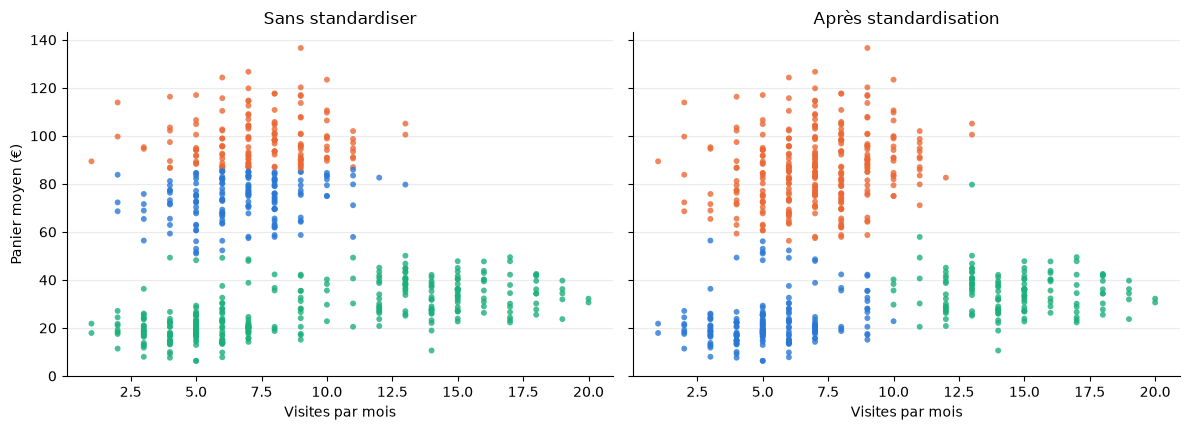

In [13]:
from sklearn.preprocessing import StandardScaler

paire = clients[["visites_par_mois", "panier_moyen"]]
paire_std = StandardScaler().fit_transform(paire)

km_brut = KMeans(n_clusters=3, n_init=10, random_state=42).fit(paire)
km_std = KMeans(n_clusters=3, n_init=10, random_state=42).fit(paire_std)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=True)
for ax, modele, titre in [(axes[0], km_brut, "Sans standardiser"), (axes[1], km_std, "Après standardisation")]:
    # le groupe qui a le moins de visites en moyenne reçoit la 1re couleur, etc. : le hasard ne change pas les couleurs
    ordre = paire.groupby(modele.labels_)["visites_par_mois"].mean().sort_values().index
    rang = {groupe: i for i, groupe in enumerate(ordre)}
    couleurs = [COULEURS[rang[g]] for g in modele.labels_]
    ax.scatter(paire["visites_par_mois"], paire["panier_moyen"], s=18, c=couleurs, alpha=0.8, edgecolor="none")
    ax.set_title(titre)
    ax.set_xlabel("Visites par mois")
axes[0].set_ylabel("Panier moyen (€)")
plt.tight_layout()
plt.show()

À gauche, les groupes se découpent en **tranches horizontales** : seul le **panier** compte, les visites sont ignorées. À
droite, **les deux colonnes comptent à égalité** : on distingue les clients qui viennent souvent (à droite) de ceux qui
viennent peu (à gauche). C'est la **standardisation** de la séance 1 : chaque colonne est ramenée à une moyenne de 0 et à
un écart-type de 1.

**Le clustering se fait toujours sur des données standardisées.** (Ici, pas de découpage train/test : il n'y a pas de
réponse à prédire, on explore le fichier entier.)

In [14]:
X = clients[colonnes]                          # les 5 colonnes, sans le numéro de carte
X_std = StandardScaler().fit_transform(X)

(pd.DataFrame(X_std, columns=colonnes).describe().loc[["mean", "std"]].round(2) + 0.0)       # + 0.0 : écrit 0 au lieu de -0

,age,visites_par_mois,panier_moyen,part_promo,part_bio
mean,0.0,0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0


Chaque colonne a maintenant une moyenne de **0** et un écart-type de **1** : elles pèsent toutes **autant**.

## 6. Combien de groupes ?

K-Means demande **K** au départ. Deux repères nous aident à le choisir.

- **Le coude (inertie).** L'inertie baisse quand K augmente (plus de groupes, donc des groupes plus serrés). On cherche
  le « coude », le K après lequel ajouter un groupe n'apporte presque plus rien.
- **La silhouette.** Pour chaque client : à quel point est-il **plus proche de son groupe** que du groupe voisin ? Le score va de
  −1 à +1 ; on cherche le K où il est **le plus haut**.

In [15]:
from sklearn.metrics import silhouette_score

lignes = []
for k in range(2, 9):
    modele = KMeans(n_clusters=k, n_init=10, random_state=42).fit(X_std)
    lignes.append({"K": k, "inertie": round(modele.inertia_), "silhouette": round(silhouette_score(X_std, modele.labels_), 2)})

choix = pd.DataFrame(lignes).set_index("K")
choix

,inertie,silhouette
K,,
2,1804,0.42
3,1013,0.51
4,453,0.61
5,409,0.53
6,380,0.42
7,360,0.34
8,331,0.23


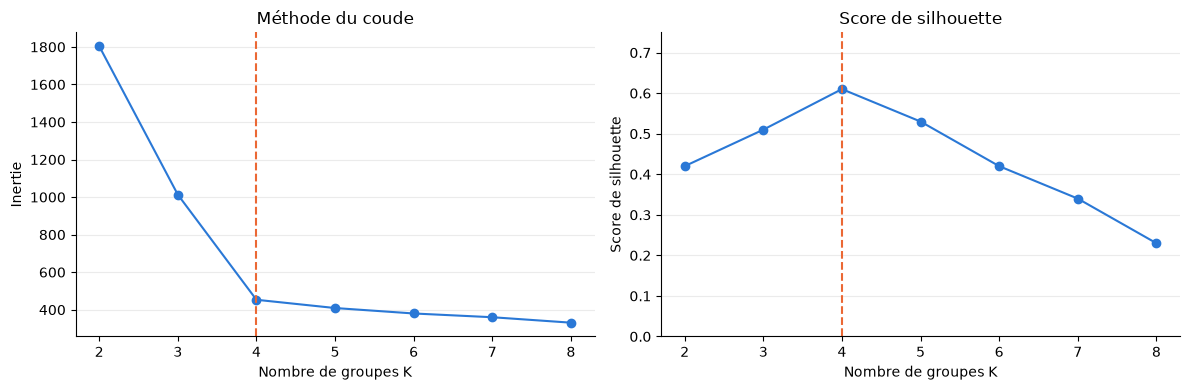

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(choix.index, choix["inertie"], color=BLEU, marker="o")
axes[0].set_xlabel("Nombre de groupes K")
axes[0].set_ylabel("Inertie")
axes[0].set_title("Méthode du coude")

axes[1].plot(choix.index, choix["silhouette"], color=BLEU, marker="o")
axes[1].set_xlabel("Nombre de groupes K")
axes[1].set_ylabel("Score de silhouette")
axes[1].set_title("Score de silhouette")
axes[1].set_ylim(0, 0.75)
for ax in axes:
    ax.axvline(4, color=ORANGE, ls="--")
plt.tight_layout()
plt.show()

Les deux repères disent la même chose : l'inertie **chute jusqu'à K = 4** (1 013 à K = 3, 453 à K = 4), puis ne baisse presque plus
(409 à K = 5), et la silhouette est **la plus haute à K = 4** (0,61). On garde **K = 4**. Dans un vrai projet, on
confirmerait avec quelqu'un qui connaît le métier.

**Et si le tirage des centres de départ est mauvais ?** Même méthode, centres de départ différents : le résultat peut changer.
On l'essaie avec 10 tirages différents, **un seul tirage par essai** (`n_init=1`).

In [17]:
inerties = []
for graine in range(10):
    modele = KMeans(n_clusters=4, init="random", n_init=1, random_state=graine).fit(X_std)
    inerties.append(round(modele.inertia_))

print("inertie de 10 tirages :", sorted(inerties))
print("le meilleur résultat possible :", min(inerties))
print("tirages qui l'atteignent :", sum(1 for i in inerties if i <= min(inerties) * 1.01), "sur 10")

inertie de 10 tirages : [453, 453, 453, 453, 453, 453, 971, 971, 984, 984]
le meilleur résultat possible : 453
tirages qui l'atteignent : 6 sur 10


Certains tirages **n'atteignent pas** le meilleur résultat : leur inertie est plus grande, les groupes sont mal découpés.
La parade : **relancer plusieurs fois** et garder le meilleur. C'est le rôle de `n_init=10` (10 tirages, on garde le meilleur),
que nous avons écrit partout.

## 7. Les quatre groupes

On lance K-Means avec K = 4 sur les 600 clients standardisés. Chaque client reçoit un numéro de groupe, rangé dans la
colonne `groupe`.

In [18]:
km = KMeans(n_clusters=4, n_init=10, random_state=42)
km.fit(X_std)

clients["groupe"] = km.labels_
clients["groupe"].value_counts().sort_index()

groupe
0    180
1    120
2    156
3    144
Name: count, dtype: int64

Les numéros (0, 1, 2, 3) sont donnés **au hasard**. Pour qu'ils ne dépendent plus du hasard, on **trie** les groupes par
âge moyen, du plus jeune au plus âgé. Puis on lit le **profil** de chaque groupe : la moyenne de chaque colonne, **dans les unités
d'origine** (années, euros…), pas en valeurs standardisées.

In [19]:
ordre = clients.groupby("groupe")["age"].mean().sort_values().index      # du plus jeune au plus âgé
rang = {groupe: i for i, groupe in enumerate(ordre)}
clients["rang"] = clients["groupe"].map(rang)                            # 0 = le plus jeune ... 3 = le plus âgé

profil = clients.groupby("rang")[colonnes].mean().round(0).astype(int)
profil.insert(0, "clients", clients["rang"].value_counts().sort_index())
profil

,clients,age,visites_par_mois,panier_moyen,part_promo,part_bio
rang,,,,,,
0,156,23,5,19,55,8
1,180,40,8,93,30,14
2,120,43,6,72,6,63
3,144,67,14,34,20,21


On lit le tableau ligne par ligne :

- **groupe 0** : 23 ans en moyenne, **5 visites**, **petits paniers (19 €)**, **55 % d'achats en promotion** → des **étudiants** ;
- **groupe 1** : 40 ans, 8 visites, **gros paniers (93 €)** → des **familles** ;
- **groupe 2** : 43 ans, 6 visites, **63 % de bio**, 6 % de promos → des **amateurs de bio** ;
- **groupe 3** : 67 ans, **14 visites par mois**, paniers moyens (34 €) → des **seniors fidèles**.

Les **noms** sont de **nous** : ce sont des hypothèses de lecture, pas des vérités de l'algorithme.

In [20]:
noms_groupes = ["Les étudiants", "Les familles", "Les amateurs de bio", "Les seniors fidèles"]
clients["profil"] = clients["rang"].map(dict(enumerate(noms_groupes)))

clients[["id_client", "age", "visites_par_mois", "panier_moyen", "profil"]].head(8)

,id_client,age,visites_par_mois,panier_moyen,profil
0,M-0001,66,12,28.7,Les seniors fidèles
1,M-0002,39,10,91.0,Les familles
2,M-0003,26,5,26.7,Les étudiants
3,M-0004,68,8,42.3,Les seniors fidèles
4,M-0005,55,14,37.1,Les seniors fidèles
5,M-0006,21,2,17.5,Les étudiants
6,M-0007,44,9,79.4,Les familles
7,M-0008,74,12,34.0,Les seniors fidèles


Le même profil en **couleurs** : orange = plus que les autres groupes, bleu = moins que les autres groupes.

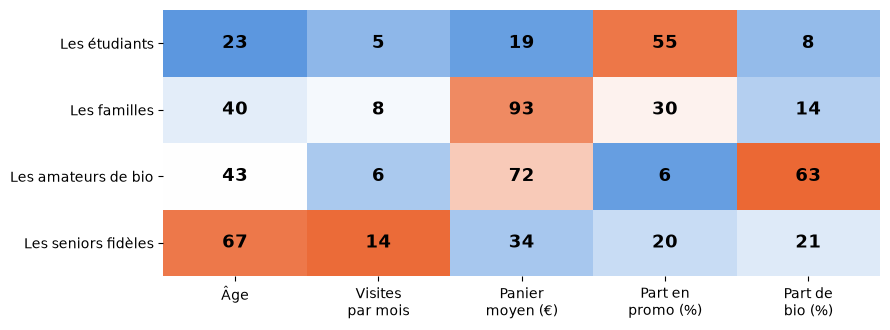

In [21]:
from matplotlib.colors import LinearSegmentedColormap

moyennes = clients.groupby("rang")[colonnes].mean()
ecarts = (moyennes - moyennes.mean()) / moyennes.std(ddof=0)             # plus ou moins que la moyenne des groupes
palette = LinearSegmentedColormap.from_list("bleu_orange", [BLEU, "white", ORANGE])

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.imshow(ecarts.values, cmap=palette, vmin=-1.7, vmax=1.7, aspect="auto")
for i in range(4):
    for j, colonne in enumerate(colonnes):
        ax.text(j, i, f"{moyennes.iloc[i, j]:.0f}", ha="center", va="center", fontsize=13, fontweight="bold")
ax.set_xticks(range(5))
ax.set_xticklabels(["Âge", "Visites\npar mois", "Panier\nmoyen (€)", "Part en\npromo (%)", "Part de\nbio (%)"])
ax.set_yticks(range(4))
ax.set_yticklabels(noms_groupes)
ax.grid(False)
for cote in ax.spines.values():
    cote.set_visible(False)
plt.tight_layout()
plt.show()

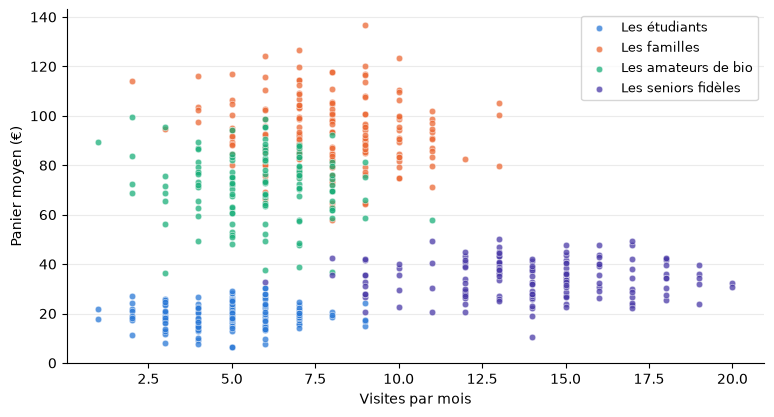

In [22]:
fig, ax = plt.subplots(figsize=(9, 4.6))
for r, nom in enumerate(noms_groupes):
    membres = clients[clients["rang"] == r]
    ax.scatter(membres["visites_par_mois"], membres["panier_moyen"], s=22, color=COULEURS[r], alpha=0.75,
               edgecolor="white", linewidth=0.4, label=nom)
ax.set_xlabel("Visites par mois")
ax.set_ylabel("Panier moyen (€)")
ax.legend(loc="upper right", fontsize=9)
plt.show()

Sur ces **deux** axes, les amateurs de bio (violet) et les familles (orange) se **mêlent** : ils se distinguent par **d'autres colonnes**
(la part de bio). Nous le reverrons avec la PCA.

**Que faire de ces groupes ?** C'est le vrai travail : en tirer des **actions**.

- **Étudiants** : promotions, petits prix.
- **Familles** : gros paniers, offres en lot, livraison.
- **Seniors fidèles** : venues fréquentes, avantages de fidélité.
- **Amateurs de bio** : gamme bio, produits premium.

---
# Partie 4 · Deux autres méthodes

## 8. Le clustering hiérarchique

Autre idée : on construit une **hiérarchie** de groupes, de bas en haut.

1. Chaque client est **un groupe**.
2. On **fusionne les deux groupes les plus proches**.
3. On répète, jusqu'à n'avoir qu'**un seul groupe**.

On commence par les 9 clients du cours. La distance entre deux groupes est ici la **distance moyenne** entre leurs membres
(`average`).

In [23]:
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage

Z = linkage(points, method="average")        # chaque ligne de Z est une fusion

fusions = []
for numero, (a, b, distance, taille) in enumerate(Z):
    nom_a = noms[int(a)] if int(a) < 9 else f"groupe {int(a) - 8}"       # les groupes créés par les fusions sont numérotés
    nom_b = noms[int(b)] if int(b) < 9 else f"groupe {int(b) - 8}"
    fusions.append({"fusion": numero + 1, "on réunit": nom_a, "avec": nom_b, "à la distance": round(distance, 2), "taille": int(taille)})

pd.DataFrame(fusions).set_index("fusion")

,on réunit,avec,à la distance,taille
fusion,,,,
1,A,C,1.00,2
2,E,F,1.00,2
3,B,groupe 1,1.21,3
4,G,H,2.00,2
5,I,groupe 4,2.24,3
6,D,groupe 2,4.04,3
7,groupe 3,groupe 6,8.15,6
8,groupe 5,groupe 7,9.38,9


Chaque ligne dit : *on réunit ces deux groupes, à cette distance*. A et C fusionnent d'abord (distance 1), de même que E et F ;
B rejoint le groupe de A et C, etc. Les **dernières** fusions se font à des distances **bien plus grandes** (8,15 puis 9,38) :
ce sont des groupes très différents.

Le **dendrogramme** dessine ces fusions : plus une fusion est **haute**, plus les groupes réunis sont **différents**. On **coupe**
l'arbre à la hauteur voulue.

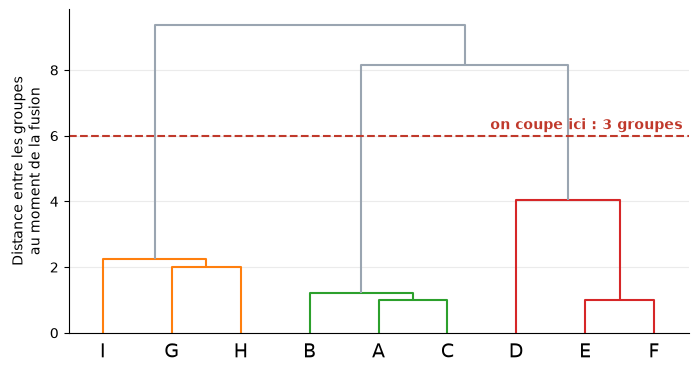

{'A': 2, 'B': 2, 'C': 2, 'D': 3, 'E': 3, 'F': 3, 'G': 1, 'H': 1, 'I': 1}


In [24]:
fig, ax = plt.subplots(figsize=(8, 4.2))
dendrogram(Z, labels=noms, ax=ax, color_threshold=6, above_threshold_color=GRIS, leaf_font_size=14)
ax.axhline(6, color="#c0392b", ls="--")
ax.text(0.99, 6.2, "on coupe ici : 3 groupes", transform=ax.get_yaxis_transform(), ha="right", color="#c0392b", fontweight="bold")
ax.set_ylabel("Distance entre les groupes\nau moment de la fusion")
ax.grid(axis="x", visible=False)
plt.show()

coupe = fcluster(Z, t=3, criterion="maxclust")
print({nom: int(g) for nom, g in zip(noms, coupe)})

Coupé à 3 groupes : **A B C**, **D E F**, **G H I**, les mêmes que K-Means. **Avantage** : on n'a pas eu à choisir K avant ;
on lit l'arbre et on coupe.

Sur les 600 clients, on demande à la méthode hiérarchique **4 groupes** (`AgglomerativeClustering`) et on compare avec K-Means :
chaque case dit combien de clients ont reçu tel groupe de K-Means (en ligne) et tel groupe hiérarchique (en colonne).

In [25]:
from sklearn.cluster import AgglomerativeClustering

hier = AgglomerativeClustering(n_clusters=4, linkage="ward").fit(X_std)

# on range les groupes hiérarchiques de la même façon : du plus jeune au plus âgé
ordre_h = clients.groupby(hier.labels_)["age"].mean().sort_values().index
rang_h = {groupe: i for i, groupe in enumerate(ordre_h)}
clients["rang_hier"] = [rang_h[g] for g in hier.labels_]

croisement = pd.crosstab(clients["profil"], clients["rang_hier"].map(dict(enumerate(noms_groupes))), rownames=["K-Means"], colnames=["Hiérarchique"])
croisement.loc[noms_groupes, noms_groupes]

Hiérarchique,Les étudiants,Les familles,Les amateurs de bio,Les seniors fidèles
K-Means,,,,
Les étudiants,156,0,0,0
Les familles,0,180,0,0
Les amateurs de bio,0,0,120,0
Les seniors fidèles,0,0,0,144


Les deux méthodes **s'accordent entièrement** : tous les clients sont sur la diagonale, aucun n'est rangé dans un autre groupe. Quand les groupes
sont nets, plusieurs méthodes trouvent les mêmes.

## 9. DBSCAN : les zones denses

**DBSCAN** ne cherche pas des centres : il cherche des **zones denses** en points, séparées par du vide. Deux réglages :

- **eps** (ε) : le **rayon** du cercle de voisinage autour d'un point ;
- **min_samples** : le **nombre minimal** de points dans ce cercle pour que le point soit un **noyau**.

Un point est un **noyau** (assez de voisins), un **bord** (voisin d'un noyau) ou du **bruit** (isolé : dans aucun groupe, noté `-1`).

On l'essaie sur un fichier de **formes** : deux croissants entrelacés et quelques points isolés, que K-Means n'aime pas.

(310, 2)


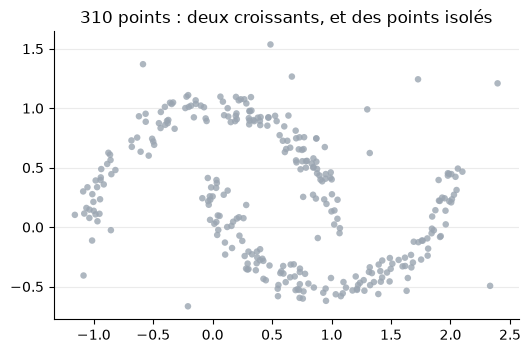

In [26]:
formes = pd.read_csv("donnees/formes.csv")
print(formes.shape)

plt.figure(figsize=(6, 4))
plt.scatter(formes["x"], formes["y"], s=22, color=GRIS, alpha=0.8, edgecolor="none")
plt.gca().set_aspect("equal")
plt.title("310 points : deux croissants, et des points isolés")
plt.show()

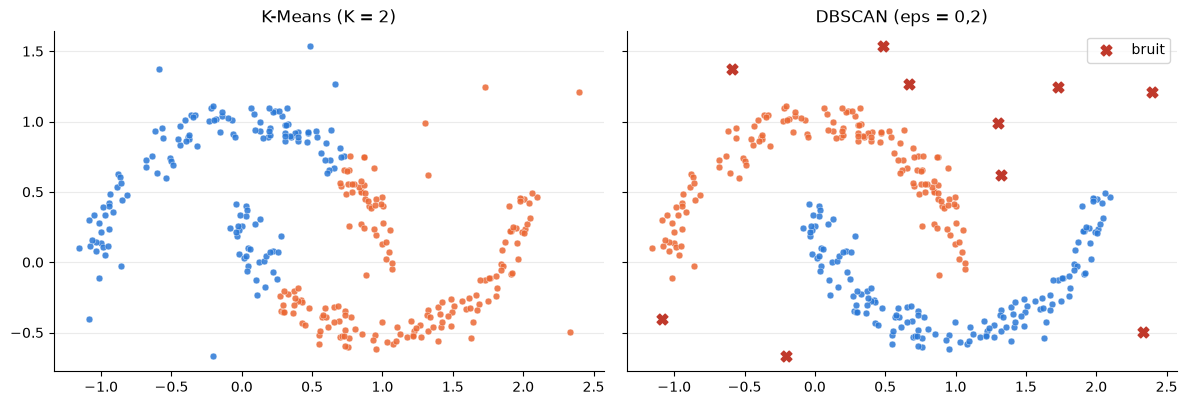

DBSCAN : 2 groupes, 10 points de bruit


In [27]:
from sklearn.cluster import DBSCAN

km_formes = KMeans(n_clusters=2, n_init=10, random_state=42).fit(formes)
db = DBSCAN(eps=0.2, min_samples=5).fit(formes)

fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharex=True, sharey=True)
for ax, etiq, titre in [(axes[0], km_formes.labels_, "K-Means (K = 2)"), (axes[1], db.labels_, "DBSCAN (eps = 0,2)")]:
    for g in sorted(set(etiq)):
        m = etiq == g
        if g == -1:
            ax.scatter(formes.loc[m, "x"], formes.loc[m, "y"], s=60, marker="X", color="#c0392b", label="bruit", zorder=5)
        else:
            ax.scatter(formes.loc[m, "x"], formes.loc[m, "y"], s=24, color=COULEURS[g], alpha=0.85, edgecolor="white", linewidth=0.3)
    ax.set_title(titre)
    ax.set_aspect("equal")
axes[1].legend(loc="upper right")
plt.tight_layout()
plt.show()

print("DBSCAN :", len(set(db.labels_) - {-1}), "groupes,", int((db.labels_ == -1).sum()), "points de bruit")

K-Means cherche des groupes **en boule** autour d'un centre : il **coupe les croissants en deux**. DBSCAN **suit la forme**,
trouve **2 groupes** et met de côté les **10 points isolés** (le bruit).

Le réglage **eps** compte : on l'essaie avec trois valeurs.

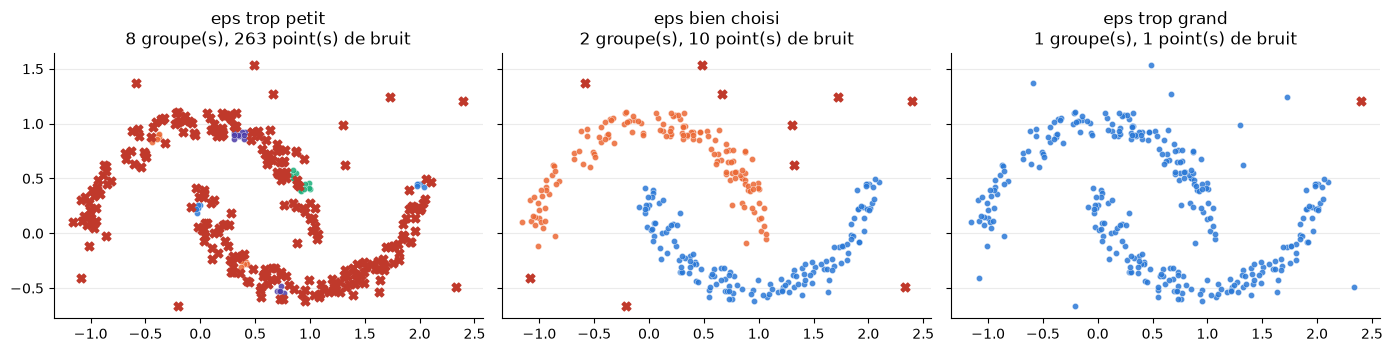

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharex=True, sharey=True)
for ax, eps, titre in zip(axes, [0.05, 0.2, 0.6], ["eps trop petit", "eps bien choisi", "eps trop grand"]):
    etiq = DBSCAN(eps=eps, min_samples=5).fit(formes).labels_
    groupes = sorted(g for g in set(etiq) if g != -1)
    for g in groupes:
        m = etiq == g
        ax.scatter(formes.loc[m, "x"], formes.loc[m, "y"], s=20, color=COULEURS[g % 4], alpha=0.85, edgecolor="white", linewidth=0.3)
    m = etiq == -1
    ax.scatter(formes.loc[m, "x"], formes.loc[m, "y"], s=40, marker="X", color="#c0392b", zorder=5)
    ax.set_title(f"{titre}\n{len(groupes)} groupe(s), {int(m.sum())} point(s) de bruit")
    ax.set_aspect("equal")
plt.tight_layout()
plt.show()

- **eps trop petit** : presque tout devient du **bruit**.
- **eps trop grand** : tout **fusionne** en un seul groupe.

Comme K pour K-Means, **eps est notre choix** : on essaie plusieurs valeurs et on **regarde** le résultat.

| Méthode | Quand l'utiliser | Avantage | Limite |
|---|---|---|---|
| **K-Means** | groupes en boule, on a une idée du nombre | rapide, simple | il faut choisir K ; les formes courbes sont ratées |
| **Hiérarchique** | on veut voir l'arbre des ressemblances, peu de données | pas de K à l'avance | lent sur de gros fichiers |
| **DBSCAN** | formes quelconques, points isolés à repérer | trouve le bruit | il faut choisir eps et min_samples |

---
# Partie 5 · Voir cinq colonnes sur un plan : la PCA

## 10. La PCA

Nos clients ont **5 colonnes** : on ne peut pas les dessiner. La **PCA** (analyse en composantes principales) fait ce qu'on
fait en photographiant un objet en 3D : elle choisit **l'angle qui le montre le mieux**. Concrètement, elle cherche les **axes
le long desquels les clients s'étalent le plus**, et projette dessus. **5 colonnes deviennent 2 axes**, qu'on peut dessiner.

In [29]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)
plan = pca.fit_transform(X_std)          # chaque client a maintenant 2 coordonnées : (axe 1, axe 2)

print("part de l'information gardée par l'axe 1 :", round(pca.explained_variance_ratio_[0], 2))
print("part de l'information gardée par l'axe 2 :", round(pca.explained_variance_ratio_[1], 2))
print("les deux axes ensemble                    :", round(pca.explained_variance_ratio_.sum(), 2))

part de l'information gardée par l'axe 1 : 0.48
part de l'information gardée par l'axe 2 : 0.3
les deux axes ensemble                    : 0.78


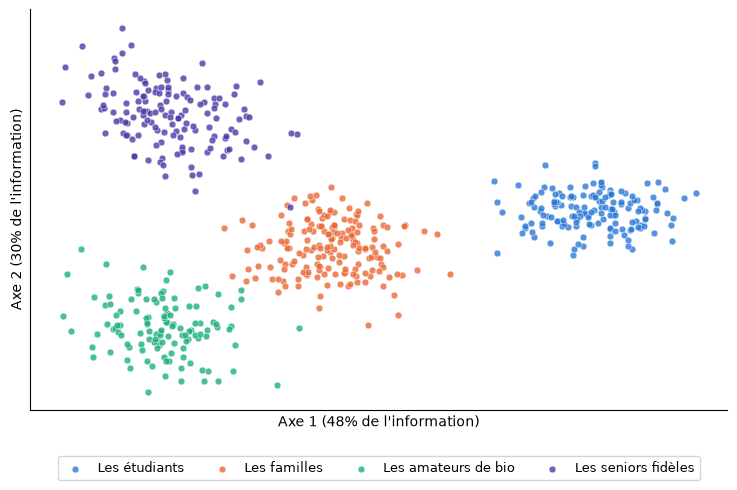

In [30]:
fig, ax = plt.subplots(figsize=(9, 5.2))
for r, nom in enumerate(noms_groupes):
    m = (clients["rang"] == r).to_numpy()
    ax.scatter(plan[m, 0], plan[m, 1], s=24, color=COULEURS[r], alpha=0.8, edgecolor="white", linewidth=0.4, label=nom)
ax.set_xlabel(f"Axe 1 ({pca.explained_variance_ratio_[0]:.0%} de l'information)")
ax.set_ylabel(f"Axe 2 ({pca.explained_variance_ratio_[1]:.0%} de l'information)")
ax.set_xticks([])
ax.set_yticks([])
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=4, fontsize=9)
plt.show()

Les deux axes gardent **78 %** de l'information des 5 colonnes, et les **4 groupes se voient très bien**, y compris les amateurs
de bio (violet) que les deux axes précédents mélangeaient aux familles.

**Attention** : la PCA **sert à dessiner**. Les groupes ont été trouvés sur les **données standardisées d'origine** (5 colonnes),
puis **colorés** sur le plan. On ne cherche pas les groupes sur le dessin.

---
# Partie 6 · Le bilan

## À retenir

- Le **clustering** cherche des **groupes sans réponse connue** (apprentissage non supervisé) : on regroupe ce qui se ressemble.
- **Se ressembler = être proche** : la distance (Pythagore). On **standardise** donc les colonnes d'abord.
- **K-Means** : choisir K centres, rattacher chaque client au plus proche, déplacer les centres à la moyenne, recommencer. On le
  **relance plusieurs fois** (`n_init`) et on garde le meilleur.
- **Choisir K** : le coude (inertie) et la silhouette, puis le sens métier.
- **Hiérarchique** : l'arbre, sans K à l'avance. **DBSCAN** : zones denses, formes quelconques, et le bruit isolé.
- **PCA** : dessiner 5 colonnes sur un plan, **sans** chercher les groupes dessus.
- Les groupes se **nomment** et s'**interprètent** : c'est notre travail, pas celui de l'algorithme.

### Les pièges

- **Oublier de standardiser** : la colonne aux grands nombres décide seule.
- **Choisir K au hasard** : regarder le coude et la silhouette, puis le sens métier.
- **Imposer des boules à des formes courbes** : regarder les données d'abord, essayer DBSCAN.
- **Sur-interpréter** : un groupe est un regroupement de chiffres, pas une vérité ; on vérifie avec ceux qui connaissent le métier.